In [55]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import matplotlib



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_func as Treat_acoustic_func
importlib.reload(Treat_acoustic_func)
from Treat_acoustic_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_plotting as Treat_acoustic_plotting
importlib.reload(Treat_acoustic_plotting)
from Treat_acoustic_plotting import *




fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [56]:
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\Acoustic\Silice thick\holes in substrate effects'

Shape_choice = 'round'
Sizes = [ '0 nm', '5 nm', '10 nm']

Spectra_data = {}
Colors = {}
compt=0

cm = plt.get_cmap('gist_rainbow')
Colors_list = [matplotlib.colors.to_hex(cm(1.*i/np.size(Sizes))) for i in range(np.size(Sizes))]


for size in Sizes :
    Colors[size] = Colors_list[compt]
    compt +=1
    dir_spectra= dir_root + '\\' + Shape_choice
    Fname_list = ['size_sweep - r_hole ' + size]
    n_parameters=2
    Spectra_data[size]= get_raw_size_sweep_data_Nathan(dir_spectra, Fname_list, verbose=True)

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:97: ParserWarning:

Both a converter and dtype were specified for column % D (m) - only the converter will be used.

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:98: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.



Total size of raw data : 5050
----------- Find spectra size -----------
idx start : 0
value start : (5.16201410031767e-06-1.3200638655026229e-05j)
end index : 49
value end : (73.37750586689246+18.189388265433237j)
----------- Find spectra size -----------
idx start : 50
value start : (1.1163225243417876e-05+4.204377754538141e-06j)
end index : 99
value end : (73.43584633211192+18.208943684571896j)
----------- Find spectra size -----------
idx start : 100
value start : (7.849118671234842e-06-2.0649112085544823e-05j)
end index : 149
value end : (73.49306428654815+18.232269371199166j)
----------- Find spectra size -----------
idx start : 150
value start : (2.802559184824399e-06-7.795835201062594e-06j)
end index : 199
value end : (73.54553917450377+18.25696486380619j)
----------- Find spectra size -----------
idx start : 200
value start : (6.183111630264359e-06+2.021561296385954e-06j)
end index : 249
value end : (75.97360644002045+0.4780519447492944j)
----------- Find spectra size ---------

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:97: ParserWarning:

Both a converter and dtype were specified for column % D (m) - only the converter will be used.

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:98: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.



Total size of raw data : 4550
----------- Find spectra size -----------
idx start : 0
value start : (5.890499009816046e-06-1.6607110095182786e-05j)
end index : 49
value end : (70.33235066960697+0.03724561058807657j)
----------- Find spectra size -----------
idx start : 50
value start : (3.4075666204994736e-06-9.883684348359934e-06j)
end index : 99
value end : (69.25923622988657+16.269128881335718j)
----------- Find spectra size -----------
idx start : 100
value start : (1.1414170694574538e-05+4.175012253987218e-06j)
end index : 149
value end : (69.33941412330417+16.28033126177524j)
----------- Find spectra size -----------
idx start : 150
value start : (7.983811921075853e-06-2.2699343500106472e-05j)
end index : 199
value end : (69.40742935680956+16.289674078097683j)
----------- Find spectra size -----------
idx start : 200
value start : (6.128610088850095e-06-1.7305877495910242e-05j)
end index : 249
value end : (69.46607226963451+16.29756047178649j)
----------- Find spectra size ------

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:97: ParserWarning:

Both a converter and dtype were specified for column % D (m) - only the converter will be used.

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:98: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.



In [57]:
#plot_all_raw_spectra_interactive(Spectra_cylinder)

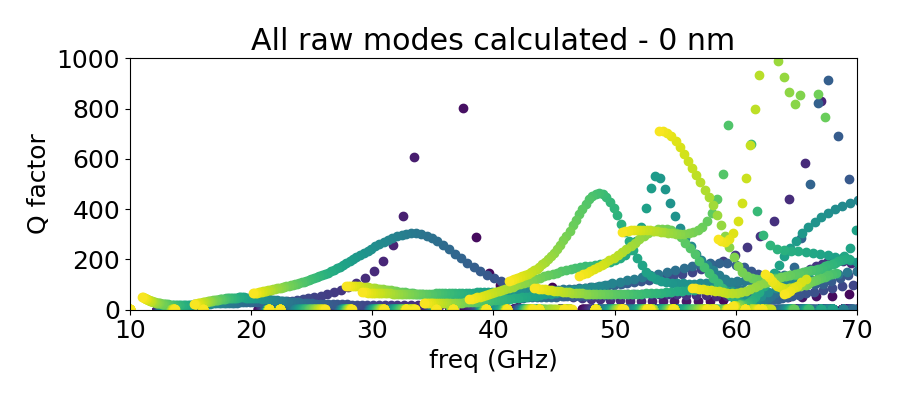

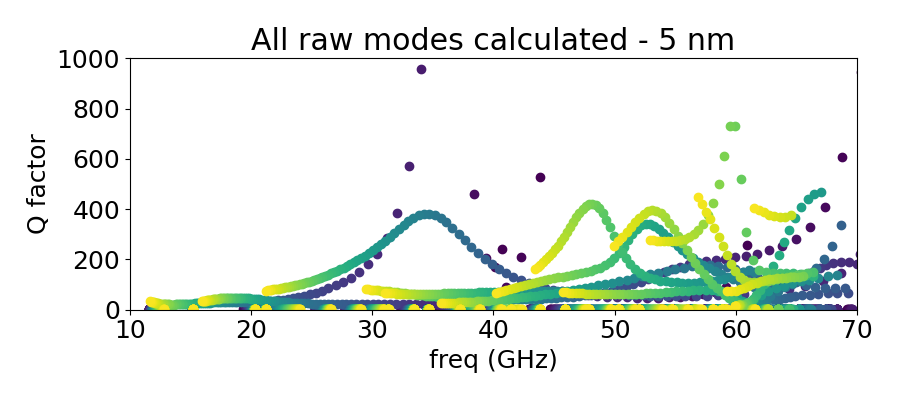

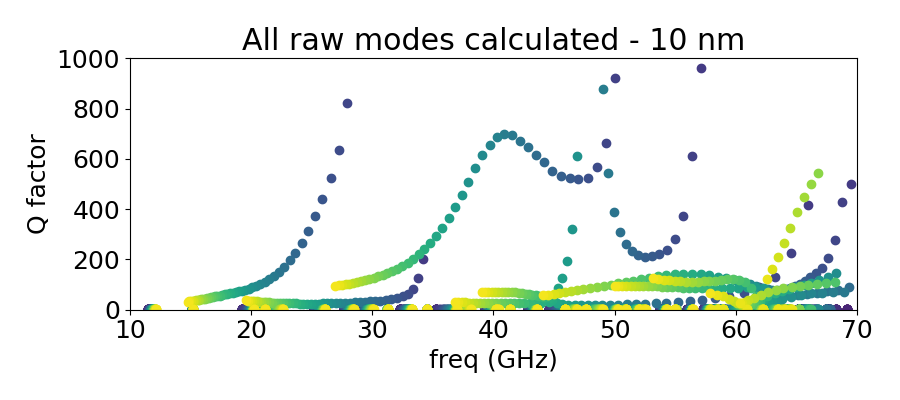

In [58]:
bottom = 0
top=1000
xlim = (10, 70)

for key in Spectra_data :
    spectra = Spectra_data[key]

    fig, ax = plt.subplots(figsize = (9,4))

    plot_all_raw_spectra(spectra, ax, plotted_key = 'Q')

    ax.set_xlabel('freq (GHz)')
    ax.set_ylabel('Q factor')
    ax.set_ylim(bottom=bottom )
    ax.set_ylim( top=top)
    ax.set_xlim(xlim)
    ax.set_title('All raw modes calculated - ' + key)
    #plt.legend(fontsize=10)
    plt.tight_layout()



In [59]:
for key in Spectra_data :
    spectra = Spectra_data[key]
    get_modes_with_Q_selection(spectra, Q_th=4)

## def freq limit functions to extract Q factor

In [60]:
## For cylinder

def f1_low(ar) :
    return(36/(ar))

def f1_high(ar) :
    return(63/(ar**0.7))

## For round corner

def f2_low(ar) :
    return(36/(ar))

def f2_high(ar) :
    return(63/(ar**0.7))


## For round
def f3_low(ar) :
    return(36/(ar))

def f3_high(ar) :
    return(60/(ar**0.7))


Boundary_func = {}
Boundary_func['0 nm'] = (f1_low, f1_high)
Boundary_func['5 nm'] = (f1_low, f1_high)
Boundary_func['10 nm'] = (f1_low, f1_high)

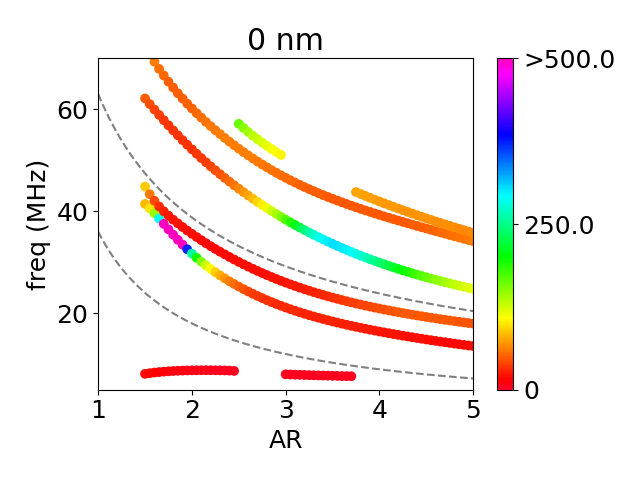

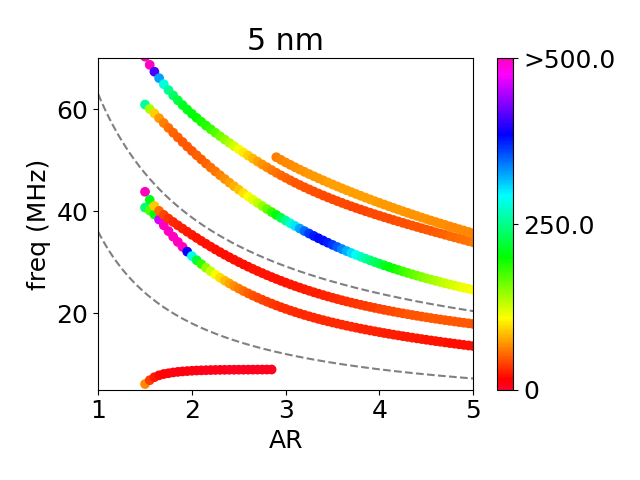

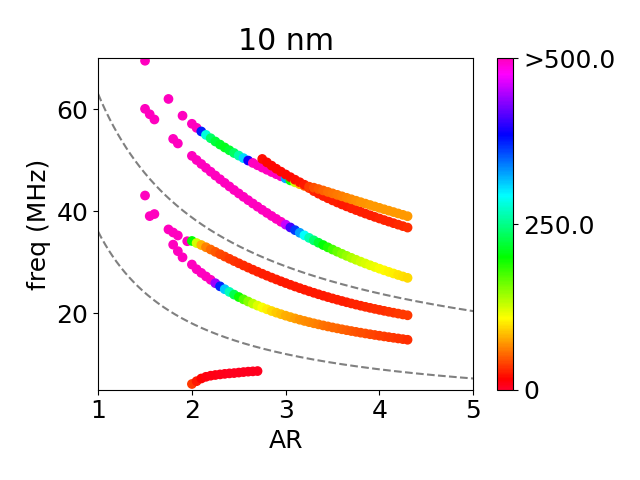

In [61]:
Q_max = 500
xlim = (1, 5)
ylim = (5, 70)
AR_array = np.linspace(1, 6, 1000)

for key in Spectra_data :
    spectra = Spectra_data[key]
   


    fig, ax = plt.subplots()

    plot_all_acoustic_modes(spectra, ax, Q_max = Q_max, n_modes = 5)

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    plt.xlabel('AR')
    plt.ylabel('freq (MHz)')
    plt.title(key)
    plt.tight_layout()

    dir_to_save = dir_root + r'\Figures'
    if not(os.path.exists(dir_to_save)) :
        os.mkdir(dir_to_save)
    os.chdir(dir_to_save)
    plt.savefig('freq(AR).pdf')
    plt.savefig('freq(AR).png')



    ax.plot(AR_array, Boundary_func[key][0](AR_array), linestyle='--', color='grey')
    ax.plot(AR_array, Boundary_func[key][1](AR_array), linestyle='--', color='grey')


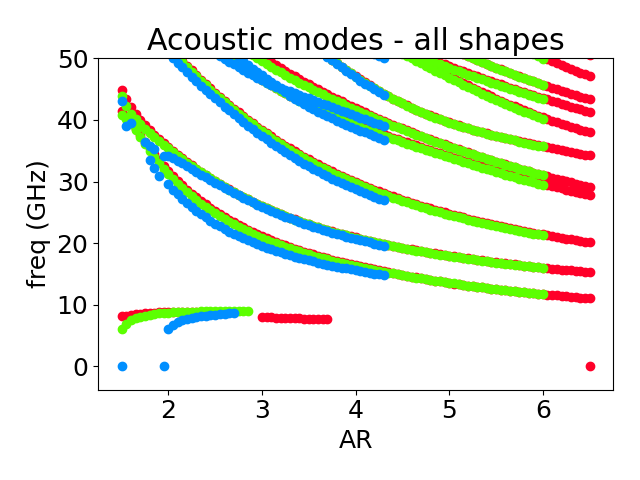

In [62]:
fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]
    


    for kkey in spectra :
        single_ND_modes = spectra[kkey]
        #print(np.sum(spectra['projection']))
        #print(spectra['eigen_freq'][np.argmax(spectra['projection'])])
        ax.scatter(single_ND_modes['AR']*np.ones(np.size(single_ND_modes['modes']['f'])), single_ND_modes['modes']['f'], color=Colors[key])


plt.title('Acoustic modes - all shapes')
plt.ylim(top=50)
plt.xlabel('AR')
plt.ylabel('freq (GHz)')
plt.tight_layout()



dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
plt.savefig('freq(AR) - ' + Shape_choice + '.pdf')
plt.savefig('freq(AR) - ' + Shape_choice + '.png')

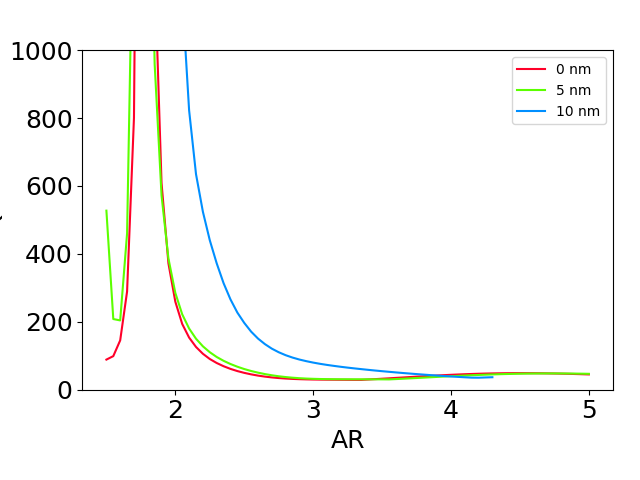

In [63]:
AR_min = 1.5
AR_max = 5

fig, ax = plt.subplots()



for key in Spectra_data :
    spectra = Spectra_data[key]
    AR, Q = get_max_Q(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1],AR_min=AR_min, AR_max=AR_max)
    ax.plot(AR, Q, color=Colors[key], label = key)




plt.xlabel('AR')
plt.ylabel('Q')
plt.legend(fontsize=10)
plt.tight_layout()
ax.set_ylim((0,1000))


dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
plt.savefig('Q(AR) - ' + Shape_choice + '.pdf')
plt.savefig('Q(AR) - ' + Shape_choice + '.png')

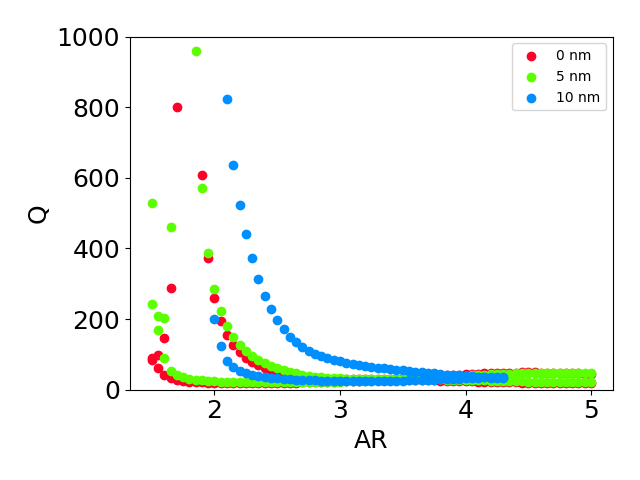

In [64]:
AR_all_shapes = {}
Q_all_shapes = {}
Freq_all_shapes = {}

fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]
    AR_all_shapes[key],  Freq_all_shapes[key], Q_all_shapes[key] = get_Q_specific_bands(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1], AR_min=AR_min, AR_max=AR_max)
    ax.scatter(AR_all_shapes[key],  Q_all_shapes[key], color=Colors[key], label = key)
ax.set_ylim((0,1000))

plt.xlabel('AR')
plt.ylabel('Q')
plt.legend(fontsize=10)
plt.tight_layout()



## Save data

In [65]:
# for key in Spectra_data :
#     spectra = Spectra_data[key]
#     dir_to_save = dir_root + r'\Treated data'
#     save_Q_with_AR_to_csv(dir_to_save, 'Selected acoustic modes', Q_all_shapes[key], AR_all_shapes[key], Freq_all_shapes[key])
#     save_freq_with_AR_to_csv(dir_to_save, 'Q and freq', spectra)